# 00 · Data foundations

What the Lovify models are actually looking at, and the three properties of the data
that determine whether any of the downstream results can be believed.

**This notebook runs with no credentials and no downloads.** It generates synthetic data
whose *structure* matches the real thing — genre-conditioned audio features, zodiac
playlists that overlap the way scraped ones do, and listeners with a known latent taste
vector. The moment you drop real files into `ml/data/raw/`, every notebook switches over
with no code change:

| file | what it is |
|---|---|
| `data/raw/tracks.csv` | the Kaggle 600k song dump (column names auto-mapped) |
| `data/raw/zodiac.csv` | your scraped zodiac playlists |
| `data/raw/listens.csv` | per-user listening histories |

Synthetic data is not a stand-in for having data. It is here so the *methods* can be
tested — in particular so we can test them against ground truth we would never have in
production.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, features as F, viz

pd.set_option("display.width", 160, "display.max_columns", 40)
print("real data on disk:", data.using_real_data())

real data on disk: {'catalog': False, 'zodiac': False, 'listens': False}


## 1 · The catalog

This stands in for the 600k-row Kaggle dump. Same 13 Spotify audio features, same shape.

In [2]:
catalog = data.load_catalog(n_synthetic=8000)
catalog.head(5)

[data] SYNTHETIC catalog (8,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.


,track_id,track_name,artist,album,genre,popularity,year,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo,loudness,duration_ms,key,mode,time_signature
0,T000000,Kenquorin Venlo,Solazavi Vexven,Torlo,metal,18,2006,0.217680,0.929446,0.209076,0.000000,0.191526,0.478736,0.517388,150.515437,-6.434694,147263.106866,4,0,4
1,T000001,Meltormel Sevilanym,Venquo Riata,Drokenfy,latin,70,2006,0.850265,0.706615,0.167420,0.105525,0.000000,0.285698,0.799482,84.445819,-7.346222,221792.854731,0,1,4
2,T000002,Azamar Tadro,Tasevaza Meltor,Nymven,edm,10,2018,0.779576,1.000000,0.000000,0.139413,0.712245,0.053235,0.536998,116.997627,-5.028111,194787.124365,3,1,4
3,T000003,Rinnox Fynym,Solazalo Quonymmel,Quoven,metal,24,2015,0.433908,0.835152,0.205386,0.040988,0.000000,0.321414,0.138523,137.491708,-2.516320,285025.731820,4,0,4
4,T000004,Vivi Tavexlo,Venquo Marvexdro,Quovi,metal,33,2023,0.353076,0.916220,0.042408,0.016457,0.090097,0.450053,0.229056,86.027469,-2.308894,225628.279640,2,0,4


## 2 · The feature-scale problem

Before any model, look at the *ranges*. This single table explains a bug that silently
sat inside the original recommender.

In [3]:
ranges = catalog[S.AUDIO_FEATURES].agg(["min", "max", "mean", "std"]).T
ranges["range"] = ranges["max"] - ranges["min"]
ranges.sort_values("range", ascending=False).round(2)

,min,max,mean,std,range
duration_ms,5000.00,967338.78,241643.19,90858.48,962338.78
tempo,0.00,232.29,113.68,27.94,232.29
loudness,-34.29,2.32,-7.97,5.58,36.61
danceability,0.00,1.00,0.57,0.20,1.00
energy,0.00,1.00,0.65,0.26,1.00
acousticness,0.00,1.00,0.26,0.27,1.00
instrumentalness,0.00,1.00,0.21,0.30,1.00
valence,0.00,1.00,0.47,0.24,1.00
liveness,0.00,0.80,0.19,0.13,0.80
speechiness,0.00,0.63,0.09,0.08,0.63


`duration_ms` spans roughly half a million. `valence` spans one.

A cosine similarity or Euclidean distance over these raw columns is **~99.99% a
measurement of song length**. The seven features we actually care about contribute
nothing measurable. Here is that stated as a fraction of total variance:

In [4]:
var = catalog[S.AUDIO_FEATURES].var()
share = (var / var.sum()).sort_values(ascending=False)
print("share of total variance carried by each raw column:")
for f, v in share.items():
    print(f"  {f:<18} {v*100:>12.8f} %")
print(f"\nduration_ms alone               : {share['duration_ms']*100:.6f} %")
print(f"all 7 bounded features combined : {share[S.BOUNDED_FEATURES].sum()*100:.8f} %")
print(f"ratio                           : {share['duration_ms']/share[S.BOUNDED_FEATURES].sum():,.0f} : 1")

share of total variance carried by each raw column:
  duration_ms         99.99999016 %
  tempo                0.00000945 %
  loudness             0.00000038 %
  instrumentalness     0.00000000 %
  acousticness         0.00000000 %
  energy               0.00000000 %
  valence              0.00000000 %
  danceability         0.00000000 %
  liveness             0.00000000 %
  speechiness          0.00000000 %

duration_ms alone               : 99.999990 %
all 7 bounded features combined : 0.00000000 %
ratio                           : 23,129,547,857 : 1


Everything downstream therefore runs through one scaler, fit on the catalog
(never on a single user), from `features.fit_scaler()`.

In [5]:
scaler = F.fit_scaler(catalog)
Z = pd.DataFrame(F.scale(catalog, scaler), columns=S.AUDIO_FEATURES)
sv = Z.var()
print("after scaling, every feature carries equal weight:")
print((sv / sv.sum() * 100).round(2).to_string())

after scaling, every feature carries equal weight:
danceability        10.0
energy              10.0
speechiness         10.0
acousticness        10.0
instrumentalness    10.0
liveness            10.0
valence             10.0
tempo               10.0
loudness            10.0
duration_ms         10.0


## 3 · Is there real structure to find?

A quick check that genre is learnable from audio features — if it weren't, nothing
later would be either. PCA to two dimensions, coloured by genre.

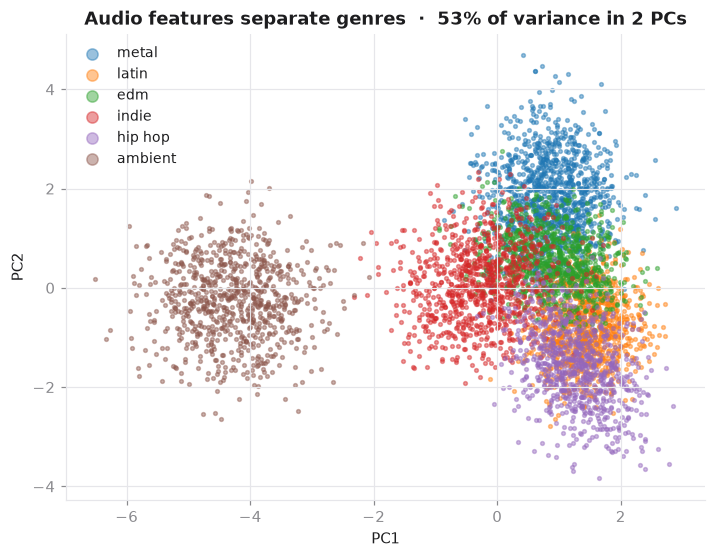

In [6]:
from sklearn.decomposition import PCA

p = PCA(n_components=2).fit(Z.to_numpy())
P = p.transform(Z.to_numpy())
top_genres = catalog[S.GENRE].value_counts().head(6).index

fig, ax = plt.subplots(figsize=(7.5, 5.5))
cmap = plt.get_cmap("tab10")
for i, g in enumerate(top_genres):
    m = (catalog[S.GENRE] == g).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=6, alpha=.45, color=cmap(i), label=g)
ax.legend(markerscale=3, fontsize=9)
ax.set_title(f"Audio features separate genres  ·  {p.explained_variance_ratio_.sum():.0%} of variance in 2 PCs")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.show()

## 4 · The zodiac scrape, and the thing hiding in it

Now the dataset behind the 76% accuracy claim. The scrape took the top playlists for
each of the 12 signs. Two consequences follow from how playlists are actually made,
and both matter enormously:

In [7]:
zodiac = data.load_zodiac(catalog)
print(f"{len(zodiac):,} rows   ·   {zodiac[S.TRACK_ID].nunique():,} unique tracks")
zodiac[[S.STAR_SIGN, S.PLAYLIST_NAME, S.TRACK_NAME, S.ARTIST, "danceability", "energy", "valence", "tempo"]].head(6)

[data] SYNTHETIC zodiac playlists. Drop your scrape at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/zodiac.csv to use real ones.
6,000 rows   ·   2,042 unique tracks


,star_sign,playlist_name,track_name,artist,danceability,energy,valence,tempo
0,Sagittarius,Sagittarius vibes #1,Vexven Drotorrin,Quolo Vimel,0.657719,0.846210,0.703735,129.321710
1,Cancer,Cancer vibes #3,Melnym Melria,Ilaken Venfymar,0.708607,0.895127,0.836032,126.715136
2,Capricorn,Capricorn vibes #9,Azamelken Fyrin,Quonym Marquoria,0.347954,1.000000,0.352211,182.452092
3,Pisces,Pisces vibes #6,Riaaza Kenmeldro,Azanym Taquonym,0.797422,0.584073,0.853050,93.838980
4,Scorpio,Scorpio vibes #9,Rinrinlo Ilatorria,Viken Melnox,0.023396,0.123544,0.364821,129.162621
5,Gemini,Gemini vibes #5,Solnox Nymria,Marmelnym Drosolta,0.791901,0.950732,0.394279,125.845777


In [8]:
per_track = zodiac.groupby(S.TRACK_ID).agg(
    rows=(S.STAR_SIGN, "size"),
    distinct_signs=(S.STAR_SIGN, "nunique"),
)

print(f"rows per unique track      : median {per_track['rows'].median():.0f}, max {per_track['rows'].max()}")
print(f"tracks appearing >1 time   : {(per_track['rows'] > 1).mean():.1%}")
print(f"tracks under >1 sign       : {(per_track['distinct_signs'] > 1).mean():.1%}  <- label noise")
print(f"rows whose track repeats\n  within its OWN sign      : "
      f"{zodiac.duplicated([S.TRACK_ID, S.STAR_SIGN], keep=False).mean():.1%}  <- leakage fuel")

rows per unique track      : median 3, max 17
tracks appearing >1 time   : 76.4%
tracks under >1 sign       : 14.5%  <- label noise
rows whose track repeats
  within its OWN sign      : 90.0%  <- leakage fuel


Read those last two numbers carefully, because notebook 01 turns on them.

**Label noise** — a track that appears under both Aries and Scorpio has two
contradictory labels. No model can be right about both. This caps how good *any*
classifier can get, no matter how clever.

**Leakage fuel** — a track repeated *within* one sign (because ten different "Aries
playlists" all contain the same hit) will land in both the training set and the test set
under a random row split. The model memorises the exact feature vector and recites the
label. It looks like accuracy. It is recall of the training set.

The second one is what produced 76%.

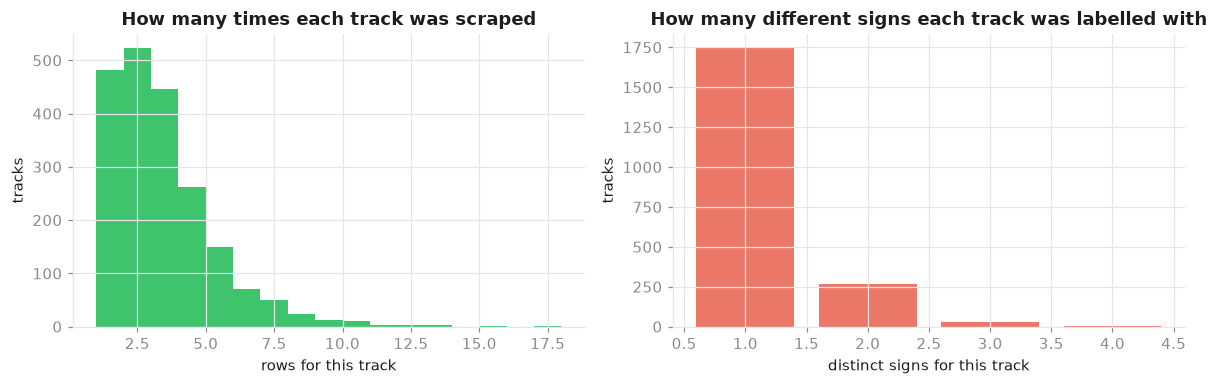

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(per_track["rows"], bins=range(1, int(per_track["rows"].max()) + 2),
             color=viz.ACCENT, alpha=.85)
axes[0].set_title("How many times each track was scraped")
axes[0].set_xlabel("rows for this track"); axes[0].set_ylabel("tracks")

sc = per_track["distinct_signs"].value_counts().sort_index()
axes[1].bar(sc.index, sc.to_numpy(), color=viz.WARN, alpha=.85)
axes[1].set_title("How many different signs each track was labelled with")
axes[1].set_xlabel("distinct signs for this track"); axes[1].set_ylabel("tracks")
plt.tight_layout(); plt.show()

### Is there any signal under the noise?

Before building a classifier, ask whether the signs differ *at all* in feature space.
A one-way ANOVA per feature across the 12 signs. Small F and large p = the signs are
indistinguishable on that feature.

In [10]:
from scipy.stats import f_oneway

rows = []
for f in S.AUDIO_FEATURES:
    groups = [g[f].to_numpy(float) for _, g in zodiac.groupby(S.STAR_SIGN)]
    stat, p = f_oneway(*groups)
    rows.append({"feature": f, "F": stat, "p_value": p})
anova = pd.DataFrame(rows).sort_values("F", ascending=False)
anova["separates_signs"] = anova["p_value"] < 0.01
anova.round(4)

,feature,F,p_value,separates_signs
4,instrumentalness,30.7556,0.0,True
9,duration_ms,26.2418,0.0,True
0,danceability,22.2128,0.0,True
8,loudness,20.7727,0.0,True
2,speechiness,20.7175,0.0,True
6,valence,20.3105,0.0,True
3,acousticness,16.7466,0.0,True
1,energy,16.0726,0.0,True
7,tempo,12.3549,0.0,True
5,liveness,6.5621,0.0,True


Whatever this table says, hold on to it — notebook 01 compares it against what
the classifier claims to be able to do. If no feature separates the signs here, a model
reporting 76% is reading something other than the features.

## 5 · Users

Listeners, each generated as a mixture over genres. The key thing synthetic users give
us that real ones never will: **a known latent taste vector**, so notebook 02 can score
similarity metrics against the truth instead of eyeballing them.

In [11]:
listens, taste = data.load_listens(catalog, n_users=250, tracks_per_user=150)
print(f"{listens[S.USER_ID].nunique()} users  ·  {len(listens):,} (user, track) rows")
listens.head(4)

[data] SYNTHETIC users. Drop real histories at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/listens.csv to use yours.


250 users  ·  37,500 (user, track) rows


,user_id,track_id,artist,genre,popularity,year,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence,tempo,loudness,duration_ms
0,U0000,T003952,Fyta Azaazator,hip hop,33,2010,0.813999,0.570060,0.287556,0.015499,0.000000,0.428360,0.601255,77.553937,-8.732701,129552.125007
1,U0000,T002210,Kenken Fynoxsol,hip hop,24,2024,0.990852,0.650788,0.429312,0.287877,0.000000,0.100947,0.290563,103.619856,-4.837154,174532.134983
2,U0000,T005148,Fyrinta Tormarnox,hip hop,22,2024,0.854587,0.627855,0.120032,0.230760,0.074314,0.170195,0.581908,111.298277,-3.786305,164719.828717
3,U0000,T006899,Nymta Nymnox,hip hop,42,2024,0.863309,0.742325,0.194634,0.187234,0.007022,0.170703,0.742562,111.800407,-6.524440,244397.872985


In [12]:
if taste is not None:
    print("ground-truth taste mixture for 3 users (fraction of listening per genre):")
    display(taste.head(3).round(3))
else:
    print("Real listens loaded -- no ground-truth taste matrix. "
          "Notebook 02 falls back to the held-out-half protocol, which needs no labels.")

ground-truth taste mixture for 3 users (fraction of listening per genre):


,hip hop,rnb,pop,indie,rock,metal,edm,ambient,jazz,country,classical,latin
U0000,0.190,0.004,0.159,0.011,0.211,0.055,0.001,0.027,0.099,0.141,0.000,0.100
U0001,0.103,0.039,0.116,0.040,0.002,0.066,0.049,0.393,0.102,0.079,0.001,0.009
U0002,0.132,0.056,0.008,0.382,0.041,0.002,0.032,0.132,0.110,0.000,0.011,0.094


### Why the "one mean vector per user" idea fails, in one picture

Collapsing a user to one mean vector is a *choice*, and the way to see whether it is a
good one is to ask what it disagrees with. Below: for every user, their top-5 matches
ranked by mean-profile distance, versus their top-5 ranked by genre overlap.

In [13]:
prof = F.mean_profile(listens, scaler)
gprof = F.genre_profile(listens)
users = list(prof.index)
Pm = prof.to_numpy()

D = np.linalg.norm(Pm[:, None, :] - Pm[None, :, :], axis=-1)
np.fill_diagonal(D, np.inf)

def top5_by_mean(u):
    i = users.index(u)
    return [users[j] for j in np.argsort(D[i])[:5]]

def top5_by_genre(u):
    ov = np.sqrt(gprof.mul(gprof.loc[u], axis=1)).sum(axis=1).drop(u)
    return list(ov.sort_values(ascending=False).head(5).index)

# How often do the two views agree on who your matches are?
agree = [len(set(top5_by_mean(u)) & set(top5_by_genre(u))) for u in users]
print("Top-5 matches: mean-profile view vs genre view")
print("  mean shared out of 5 :", round(float(np.mean(agree)), 2))
print("  pairs agreeing on 0  :", f"{np.mean(np.array(agree) == 0):.0%} of users")
print("  pairs agreeing on 4+ :", f"{np.mean(np.array(agree) >= 4):.0%} of users")

Top-5 matches: mean-profile view vs genre view
  mean shared out of 5 : 0.83
  pairs agreeing on 0  : 40% of users
  pairs agreeing on 4+ : 0% of users


In [14]:
u = users[0]
print(f"For {u}, the two methods nominate almost different people:")
print("  by mean audio profile :", top5_by_mean(u))
print("  by genre overlap      :", top5_by_genre(u))
print("  overlap               :", sorted(set(top5_by_mean(u)) & set(top5_by_genre(u))) or "none")

For U0000, the two methods nominate almost different people:
  by mean audio profile : ['U0104', 'U0173', 'U0077', 'U0055', 'U0245']
  by genre overlap      : ['U0046', 'U0064', 'U0013', 'U0048', 'U0082']
  overlap               : none


The single closest pair by mean profile: U0160 and U0218 (distance 0.139)
  U0160 top genres: [('rnb', 0.25), ('edm', 0.23), ('indie', 0.11)]
  U0218 top genres: [('edm', 0.35), ('country', 0.26), ('indie', 0.09)]


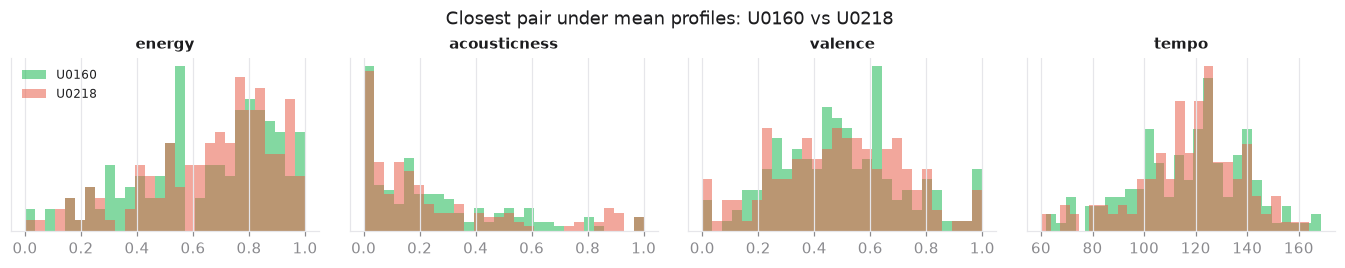

In [15]:
i, j = np.unravel_index(np.argmin(D), D.shape)
u2, v2 = users[i], users[j]
A, B = listens[listens[S.USER_ID] == u2], listens[listens[S.USER_ID] == v2]
print(f"The single closest pair by mean profile: {u2} and {v2} (distance {D[i, j]:.3f})")
for name, df in [(u2, A), (v2, B)]:
    print(f"  {name} top genres:", list(df[S.GENRE].value_counts(normalize=True).head(3).round(2).items()))

viz.feature_distributions({u2: A, v2: B}, ["energy", "acousticness", "valence", "tempo"], ncols=4)
plt.suptitle(f"Closest pair under mean profiles: {u2} vs {v2}", y=1.04)
plt.show()

The two views largely disagree about who your matches are, and they cannot both
be right. The histograms show what the mean discarded to produce its answer: two people
the mean calls near-identical still have visibly different distributions.

Which view is actually correct is an empirical question, and notebook 02 answers it by
scoring both against the ground-truth taste vectors.

Notebook 02 measures exactly how much that costs.

## What carries forward

1. **Scale before you measure.** Raw-column distance is a measurement of song length.
2. **The zodiac set contains duplicate tracks**, both within and across signs. Any
   evaluation that splits rows at random is scoring memorisation.
3. **A mean vector is not a taste.** It discards spread, which is where the signal is.

→ `01_zodiac_classifier.ipynb` takes the first and second of these apart.